## Academic Stress and Short-Term Memory


**Main outcome:** `DigitSpan_HighestSpanPassed`  
**Main predictor:** `Stress_total`

### What is included
1. Load the data and do basic checks
2. Participant characteristics/descriptive statistics
3. Reliability of the 8 academic-stress items
4. Pearson correlations (with 95% confidence intervals)
5. The main Figure
6. Linear vs. quadratic regression for the Yerkes-Dodson hypothesis
7. A compact table for the four predictor/outcome combinations
8. Two short robustness checks (Spearman and Cook's distance)


## 1. Import libraries and load the dataset


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

DATA_FILE = "stress_digitspan_data.xlsx - collected_data.csv"
df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (60, 17)


,Participant_ID,Age,Gender,Year_of_Study,Department,Stress_q1,Stress_q2,Stress_q3,Stress_q4,Stress_q5,Stress_q6,Stress_q7,Stress_q8,Stress_total,Current_Stress,DigitSpan_CorrectTrials,DigitSpan_HighestSpanPassed
0,P01,24,M,4th,CSE,4,5,4,5,4,4,3,5,34,4,9,7
1,P02,25,F,4th,BIO,3,3,4,4,3,3,3,4,27,0,11,8
2,P03,23,F,3rd,BBA,5,5,5,5,5,5,5,5,40,7,11,8
3,P04,25,M,4th,CSE,3,2,4,3,2,3,4,2,23,6,8,5
4,P05,24,M,4th,CSE,2,3,2,2,3,2,1,2,17,5,12,7


## 2. Basic data checks

In [ ]:
stress_items = [f"Stress_q{i}" for i in range(1, 9)]
recalculated_stress = df[stress_items].sum(axis=1)

print("Number of participants:", len(df))
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate participant IDs:", int(df["Participant_ID"].duplicated().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Stress_total scoring errors:", int((recalculated_stress != df["Stress_total"]).sum()))

Number of participants: 60
Total missing values: 0
Duplicate participant IDs: 0
Exact duplicate rows: 0
Stress_total scoring errors: 0


## 3. Participant characteristics and descriptive statistics

In [ ]:
print(f"Age: M = {df['Age'].mean():.2f}, SD = {df['Age'].std():.2f}, range = {df['Age'].min()}–{df['Age'].max()}")

print("\nGender:")
print(df["Gender"].value_counts().to_frame("n").assign(percent=lambda x: (x["n"] / len(df) * 100).round(1)))

print("\nYear of study:")
print(df["Year_of_Study"].value_counts().to_frame("n").assign(percent=lambda x: (x["n"] / len(df) * 100).round(1)))

print("\nDepartment:")
print(df["Department"].value_counts().to_frame("n").assign(percent=lambda x: (x["n"] / len(df) * 100).round(1)))

main_vars = {
    "Stress_total": "Academic stress total",
    "Current_Stress": "Current stress",
    "DigitSpan_HighestSpanPassed": "Highest digit span passed",
    "DigitSpan_CorrectTrials": "Correct digit span trials",
}

descriptive = pd.DataFrame({
    "N": df[list(main_vars)].count(),
    "M": df[list(main_vars)].mean(),
    "SD": df[list(main_vars)].std(),
    "Min": df[list(main_vars)].min(),
    "Max": df[list(main_vars)].max(),
}).rename(index=main_vars).round(2)

descriptive

Age: M = 23.95, SD = 0.70, range = 23–25

Gender:
         n  percent
Gender             
M       38     63.3
F       22     36.7

Year of study:
                n  percent
Year_of_Study             
4th            44     73.3
3rd            16     26.7

Department:
             n  percent
Department             
CSE         36     60.0
EEE          7     11.7
BIO          6     10.0
BBA          5      8.3
ENG          2      3.3
MNS          2      3.3
LAW          2      3.3


,N,M,SD,Min,Max
Academic stress total,60,23.95,7.76,10,40
Current stress,60,5.30,2.07,0,9
Highest digit span passed,60,6.32,1.40,4,9
Correct digit span trials,60,10.00,2.46,5,14


## 4. Reliability of the 8 academic-stress items


In [ ]:
item_scores = df[stress_items]
k = len(stress_items)

cronbach_alpha = (k / (k - 1)) * (
    1 - item_scores.var(ddof=1).sum() / item_scores.sum(axis=1).var(ddof=1)
)

print(f"Cronbach's alpha = {cronbach_alpha:.3f}")

Cronbach's alpha = 0.965


## 5. Pearson correlations

In [ ]:
def pearson_with_ci(x, y):
    r, p = stats.pearsonr(x, y)
    n = len(x)
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    low, high = np.tanh([z - 1.96 * se, z + 1.96 * se])
    return r, p, low, high

pairs = [
    ("Stress_total", "Current_Stress", "Academic stress vs current stress"),
    ("Stress_total", "DigitSpan_HighestSpanPassed", "Academic stress vs highest span"),
    ("Stress_total", "DigitSpan_CorrectTrials", "Academic stress vs correct trials"),
    ("Current_Stress", "DigitSpan_HighestSpanPassed", "Current stress vs highest span"),
    ("Current_Stress", "DigitSpan_CorrectTrials", "Current stress vs correct trials"),
]

rows = []
for xvar, yvar, label in pairs:
    r, p, low, high = pearson_with_ci(df[xvar], df[yvar])
    rows.append({
        "Relationship": label,
        "r": r,
        "p": p,
        "95% CI low": low,
        "95% CI high": high,
    })

correlations = pd.DataFrame(rows)
correlations.round({"r": 3, "p": 4, "95% CI low": 3, "95% CI high": 3})

,Relationship,r,p,95% CI low,95% CI high
0,Academic stress vs current stress,0.863,0.0000,0.780,0.916
1,Academic stress vs highest span,-0.346,0.0068,-0.551,-0.101
2,Academic stress vs correct trials,-0.400,0.0015,-0.594,-0.162
3,Current stress vs highest span,-0.427,0.0007,-0.614,-0.194
4,Current stress vs correct trials,-0.390,0.0021,-0.586,-0.151


## 6. The main figure

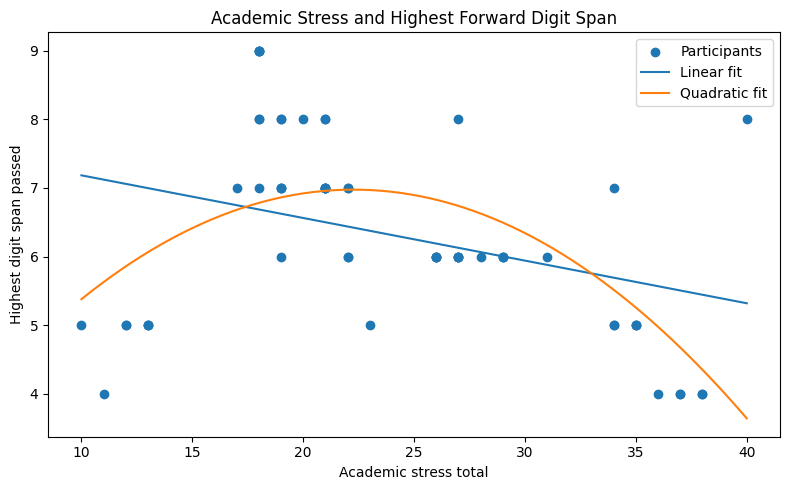

In [ ]:
x = df["Stress_total"].to_numpy()
y = df["DigitSpan_HighestSpanPassed"].to_numpy()

linear_coef = np.polyfit(x, y, 1)
quadratic_coef = np.polyfit(x, y, 2)
plot_x = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, label="Participants")
plt.plot(plot_x, np.polyval(linear_coef, plot_x), label="Linear fit")
plt.plot(plot_x, np.polyval(quadratic_coef, plot_x), label="Quadratic fit")
plt.xlabel("Academic stress total")
plt.ylabel("Highest digit span passed")
plt.title("Academic Stress and Highest Forward Digit Span")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Hypothesis test: academic stress → highest digit span

The main theoretical question is whether a **quadratic model** explains the data better than a simple straight line.

The predictor is centered before squaring it. Centering does not change the shape of the model; it only makes the coefficients easier to estimate and interpret.

In [ ]:
x = df["Stress_total"]
y = df["DigitSpan_HighestSpanPassed"]

# Center stress around its sample mean
x_centered = x - x.mean()

# Linear model: outcome = b0 + b1(stress)
X_linear = sm.add_constant(pd.DataFrame({"stress": x_centered}))
linear_model = sm.OLS(y, X_linear).fit()

# Quadratic model: outcome = b0 + b1(stress) + b2(stress^2)
X_quadratic = sm.add_constant(pd.DataFrame({
    "stress": x_centered,
    "stress_squared": x_centered ** 2,
}))
quadratic_model = sm.OLS(y, X_quadratic).fit()

# Change in R-squared when the squared term is added
delta_r2 = quadratic_model.rsquared - linear_model.rsquared
n = len(df)
f_change = (delta_r2 / 1) / ((1 - quadratic_model.rsquared) / (n - 3))
p_change = stats.f.sf(f_change, 1, n - 3)

# Peak of the fitted inverted-U, converted back to the original stress scale
b1 = quadratic_model.params["stress"]
b2 = quadratic_model.params["stress_squared"]
peak = x.mean() - b1 / (2 * b2)

print(f"Linear R² = {linear_model.rsquared:.3f}")
print(f"Quadratic R² = {quadratic_model.rsquared:.3f}")
print(f"Adjusted R² = {quadratic_model.rsquared_adj:.3f}")
print(f"Quadratic model F(2, 57) = {quadratic_model.fvalue:.2f}, p = {quadratic_model.f_pvalue:.6f}")
print(f"Squared term b = {b2:.4f}, SE = {quadratic_model.bse['stress_squared']:.4f}, p = {quadratic_model.pvalues['stress_squared']:.6f}")
print(f"ΔR² = {delta_r2:.3f}")
print(f"F-change(1, 57) = {f_change:.2f}, p = {p_change:.6f}")
print(f"Estimated peak stress score = {peak:.2f}")

Linear R² = 0.119
Quadratic R² = 0.351
Adjusted R² = 0.328
Quadratic model F(2, 57) = 15.38, p = 0.000005
Squared term b = -0.0106, SE = 0.0024, p = 0.000034
ΔR² = 0.231
F-change(1, 57) = 20.28, p = 0.000034
Estimated peak stress score = 22.27


### Interpretation

The key number is the coefficient for `stress_squared`. It is **negative and statistically significant**, so the fitted relationship curves downward. The quadratic model also explains substantially more variance than the linear model. Therefore, the observed pattern is **consistent with an inverted-U relationship**.

Because this is a correlational study, this does **not** prove that stress caused the memory differences.

## 8. Compact Table


In [ ]:
def quadratic_summary(xvar, yvar, label):
    x = df[xvar]
    y = df[yvar]
    xc = x - x.mean()

    X1 = sm.add_constant(pd.DataFrame({"x": xc}))
    X2 = sm.add_constant(pd.DataFrame({"x": xc, "x_squared": xc ** 2}))

    m1 = sm.OLS(y, X1).fit()
    m2 = sm.OLS(y, X2).fit()

    r, p = stats.pearsonr(x, y)
    delta = m2.rsquared - m1.rsquared
    peak = x.mean() - m2.params["x"] / (2 * m2.params["x_squared"])

    return {
        "Predictor / outcome": label,
        "Pearson r": r,
        "Pearson p": p,
        "Quadratic R²": m2.rsquared,
        "ΔR²": delta,
        "Squared term b": m2.params["x_squared"],
        "Squared-term p": m2.pvalues["x_squared"],
        "Estimated peak": peak,
    }

summary_table = pd.DataFrame([
    quadratic_summary("Stress_total", "DigitSpan_HighestSpanPassed", "Academic stress / highest span"),
    quadratic_summary("Stress_total", "DigitSpan_CorrectTrials", "Academic stress / correct trials"),
    quadratic_summary("Current_Stress", "DigitSpan_HighestSpanPassed", "Current stress / highest span"),
    quadratic_summary("Current_Stress", "DigitSpan_CorrectTrials", "Current stress / correct trials"),
])

summary_table.round({
    "Pearson r": 3,
    "Pearson p": 4,
    "Quadratic R²": 3,
    "ΔR²": 3,
    "Squared term b": 4,
    "Squared-term p": 5,
    "Estimated peak": 2,
})

,Predictor / outcome,Pearson r,Pearson p,Quadratic R²,ΔR²,Squared term b,Squared-term p,Estimated peak
0,Academic stress / highest span,-0.346,0.0068,0.351,0.231,-0.0106,0.00003,22.27
1,Academic stress / correct trials,-0.400,0.0015,0.487,0.327,-0.0222,0.00000,22.35
2,Current stress / highest span,-0.427,0.0007,0.420,0.238,-0.1217,0.00001,4.10
3,Current stress / correct trials,-0.390,0.0021,0.499,0.347,-0.2584,0.00000,4.39


# Optional robustness checks


## 9. Spearman correlations


In [ ]:
spearman_rows = []
for xvar, yvar, label in pairs[1:]:   # the four stress-memory pairs
    rho, p = stats.spearmanr(df[xvar], df[yvar])
    spearman_rows.append({"Relationship": label, "Spearman rho": rho, "p": p})

pd.DataFrame(spearman_rows).round({"Spearman rho": 3, "p": 4})

,Relationship,Spearman rho,p
0,Academic stress vs highest span,-0.354,0.0056
1,Academic stress vs correct trials,-0.407,0.0013
2,Current stress vs highest span,-0.424,0.0007
3,Current stress vs correct trials,-0.387,0.0023


## 10. Cook's distance sensitivity check

 The usual simple screening rule `Cook's D > 4/N` is used here.

In [ ]:
def cooks_sensitivity(xvar, label):
    yvar = "DigitSpan_HighestSpanPassed"
    x = df[xvar]
    y = df[yvar]
    xc = x - x.mean()

    X = sm.add_constant(pd.DataFrame({"x": xc, "x_squared": xc ** 2}))
    model = sm.OLS(y, X).fit()

    cooks_d = model.get_influence().cooks_distance[0]
    cutoff = 4 / len(df)
    flagged_positions = np.where(cooks_d > cutoff)[0]
    flagged_ids = df.iloc[flagged_positions]["Participant_ID"].tolist()

    reduced = df.drop(df.index[flagged_positions]).copy()
    xr = reduced[xvar]
    yr = reduced[yvar]
    xrc = xr - xr.mean()
    Xr = sm.add_constant(pd.DataFrame({"x": xrc, "x_squared": xrc ** 2}))
    reduced_model = sm.OLS(yr, Xr).fit()

    peak = xr.mean() - reduced_model.params["x"] / (2 * reduced_model.params["x_squared"])

    return {
        "Model": label,
        "Cook's D cutoff": cutoff,
        "Flagged cases": len(flagged_ids),
        "Flagged participant IDs": ", ".join(flagged_ids),
        "R² after exclusion": reduced_model.rsquared,
        "Squared-term p after exclusion": reduced_model.pvalues["x_squared"],
        "Peak after exclusion": peak,
    }

sensitivity = pd.DataFrame([
    cooks_sensitivity("Stress_total", "Academic stress → highest span"),
    cooks_sensitivity("Current_Stress", "Current stress → highest span"),
])

sensitivity.round({
    "Cook's D cutoff": 3,
    "R² after exclusion": 3,
    "Squared-term p after exclusion": 6,
    "Peak after exclusion": 2,
})

,Model,Cook's D cutoff,Flagged cases,Flagged participant IDs,R² after exclusion,Squared-term p after exclusion,Peak after exclusion
0,Academic stress → highest span,0.067,2,"P03, P07",0.542,0.0,21.73
1,Current stress → highest span,0.067,2,"P02, P07",0.555,0.0,4.69
